In [ ]:
# === CABECALHO ACADEMICO (gerado por scripts/apply_header.py) ===
# Universidade Presbiteriana Mackenzie
# Disciplina: Inteligência Artificial
# Projeto: Previsão de desempenho de jogadores da NBA (pontos por jogo)
#
# INTEGRANTES DO GRUPO:
#   - Rodrigo Lucas Mascarenhas Leite Oliveira - TIA 10427925
#   - André Ihsan Ward - TIA 10425684
#
# ARQUIVO: notebooks/02_baselines_e_regressao.ipynb
# SINTESE: Baselines e modelos de regressão: validação temporal e teste.
#
# HISTORICO DE ALTERACOES:
#   data       | autor      | descricao
#   -----------|------------|-------------------------------------------
#   2026-11-15 | Rodrigo    | Versão inicial.
# === FIM DO CABECALHO ===


# 02 - Baselines e modelos de regressão

Objetivo: prever `y_pts` (pontos no jogo) usando só informação pré-jogo, e verificar se modelos supervisionados superam as médias recentes que se usam na prática.

**Protocolo** (código em `src/train.py` e `src/evaluate.py`):
1. hiperparâmetros por validação cruzada **temporal** dentro do treino (2021-22 → 2022-23; 2021-23 → 2023-24);
2. escolha do modelo na **validação** (2024-25);
3. **teste** (2025-26) avaliado uma única vez (`python -m src.evaluate --final`).

Este notebook não retreina a grade inteira (isso está em `python -m src.train`): ele reproduz a validação cruzada de um modelo para mostrar o mecanismo e lê os resultados salvos.

In [2]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 30)
TV = json.loads(Path("results/metrics/treino_validacao.json").read_text(encoding="utf-8"))
TF = json.loads(Path("results/metrics/test_final.json").read_text(encoding="utf-8"))

## 1. Dados e divisão temporal

In [3]:
from src.modeling import load_dataset, get_split, season_folds, assert_disjoint_temporal, FEATURE_FAMILIES
from src.features import PRE_GAME_FEATURES
df = load_dataset()
assert_disjoint_temporal(df)   # falha se treino/validação/teste se sobrepõem
df.groupby("split").agg(linhas=("y_pts", "size"), inicio=("GAME_DATE", "min"), fim=("GAME_DATE", "max"),
                        temporadas=("SEASON", lambda s: ", ".join(sorted(s.unique())))).loc[["train", "val", "test"]]

,linhas,inicio,fim,temporadas
split,,,,
train,50045,2021-11-07,2024-04-14,"2021-22, 2022-23, 2023-24"
val,16653,2024-11-09,2025-04-13,2024-25
test,17101,2025-11-09,2026-04-12,2025-26


In [4]:
train = get_split(df, "train")
for k, (tr, va) in enumerate(season_folds(train), 1):
    print(f"dobra {k}: treina em {sorted(train.loc[tr, 'SEASON'].unique())} -> valida em {train.loc[va, 'SEASON'].unique()[0]}")
pd.Series({fam: ", ".join(cols) for fam, cols in FEATURE_FAMILIES.items()}, name="features").to_frame()

dobra 1: treina em ['2021-22'] -> valida em 2022-23
dobra 2: treina em ['2021-22', '2022-23'] -> valida em 2023-24


,features
historico_pontos,"pts_ma3_prev, pts_ma5_prev, pts_ma10_prev, pts..."
minutos_e_papel,"min_ma3_prev, min_ma5_prev, min_ma10_prev, min..."
volume_de_jogo,"fga_ma5_prev, fg3a_ma5_prev, fta_ma5_prev, reb..."
descanso_e_mando,"rest_days, is_b2b, is_home"
adversario,"opp_def_pts_allowed_prev, opp_pace_proxy_prev,..."
calendario_do_jogador,games_played_prev


## 2. Baselines

A baseline prometida no relatório N1 é a média dos 5 jogos anteriores. Ela fica entre as mais fracas das médias recentes (só a de 3 jogos erra mais), então comparamos os modelos também com a média exponencial (fator 0,9) e com uma regressão linear de uma variável sobre ela, que verifica se o ganho vem só de reescalar a média recente. Em MAE, a régua mais exigente é a própria média exponencial e, como diagnóstico, uma regressão **mediana** sobre ela (seção 5).

In [5]:
from src.modeling import predict_baselines
from src.metrics import regression_metrics
val = get_split(df, "val")
base_val = pd.DataFrame({k: regression_metrics(val["y_pts"], p) for k, p in predict_baselines(val, train).items()}).T
base_val.sort_values("mae")[["mae", "rmse", "r2", "vies"]]

,mae,rmse,r2,vies
media_exponencial,5.053,6.491,0.450,-0.211
linear_sobre_exponencial,5.063,6.473,0.453,-0.028
media_da_temporada,5.115,6.597,0.432,-0.630
media_10_jogos,5.140,6.593,0.433,-0.075
mediana_10_jogos,5.230,6.759,0.404,-0.506
media_5_jogos,5.314,6.829,0.392,0.105
media_3_jogos,5.545,7.135,0.336,0.130
constante_mediana_treino,6.888,8.969,-0.050,-1.952
constante_media_treino,6.969,8.754,-0.000,-0.015


## 3. Validação cruzada temporal (exemplo ao vivo: Ridge)

In [6]:
from sklearn.model_selection import GridSearchCV
from src.modeling import regression_zoo
pipe, grid = regression_zoo()["ridge"]
busca = GridSearchCV(pipe, grid, cv=season_folds(train), scoring="neg_mean_absolute_error").fit(train[PRE_GAME_FEATURES], train["y_pts"])
print("pipeline:", pipe)
print("melhor alpha:", busca.best_params_, "| MAE médio nas dobras:", round(-busca.best_score_, 3))
print("MAE na validação 2024-25:", round(regression_metrics(val["y_pts"], busca.predict(val[PRE_GAME_FEATURES]))["mae"], 3))

pipeline: Pipeline(steps=[('cap',
                 FunctionTransformer(func=<function cap_rest_days at 0x0000018433C8F2E0>)),
                ('scaler', StandardScaler()), ('model', Ridge())])
melhor alpha: {'model__alpha': np.float64(0.01)} | MAE médio nas dobras: 5.016
MAE na validação 2024-25: 5.01


## 4. Todos os modelos: validação cruzada e validação 2024-25 (de `src.train`)

In [7]:
cv = pd.DataFrame({k: {"MAE CV": -v["score_cv_medio"], "parametros": v["melhores_parametros"], "tempo (s)": TV["regressao"]["tempo_s"][k]}
                   for k, v in TV["regressao"]["cv"].items()}).T
cv["MAE validação"] = [TV["regressao"]["validacao"][k]["mae"] for k in cv.index]
print("modelo final (menor MAE na validação):", TV["regressao"]["modelo_final"])
cv.sort_values("MAE validação")

modelo final (menor MAE na validação): hgb_absoluto


,MAE CV,parametros,tempo (s),MAE validação
hgb_absoluto,4.993,"{'model__min_samples_leaf': 50, 'model__max_le...",31.600,4.996
lasso,5.016,{'model__alpha': 0.0001},9.200,5.010
ridge,5.016,{'model__alpha': 0.01},7.700,5.010
hgb_poisson,5.035,"{'model__min_samples_leaf': 200, 'model__max_l...",23.000,5.012
hgb_quadratico,5.035,"{'model__min_samples_leaf': 200, 'model__max_l...",21.700,5.015
random_forest,5.025,"{'model__max_features': 0.33, 'model__min_samp...",22.200,5.025
poisson_glm,5.152,{'model__alpha': 0.1},0.900,5.104


## 5. Teste 2025-26 (avaliado uma vez)

In [8]:
t = pd.DataFrame(TF["regressao"]["teste"]).T.sort_values("mae")
t[["tipo", "mae", "rmse", "r2", "vies"]]

,tipo,mae,rmse,r2,vies
hgb_absoluto,modelo,4.924,6.374,0.445,-0.364
lasso,modelo,4.942,6.338,0.451,0.207
ridge,modelo,4.942,6.338,0.451,0.207
hgb_poisson,modelo,4.947,6.351,0.449,0.214
hgb_quadratico,modelo,4.948,6.352,0.449,0.201
random_forest,modelo,4.961,6.366,0.446,0.201
media_exponencial,baseline,4.977,6.422,0.437,-0.109
linear_sobre_exponencial,baseline,4.986,6.403,0.440,0.081
poisson_glm,modelo,5.030,6.465,0.429,-0.063
media_10_jogos,baseline,5.045,6.514,0.421,-0.013


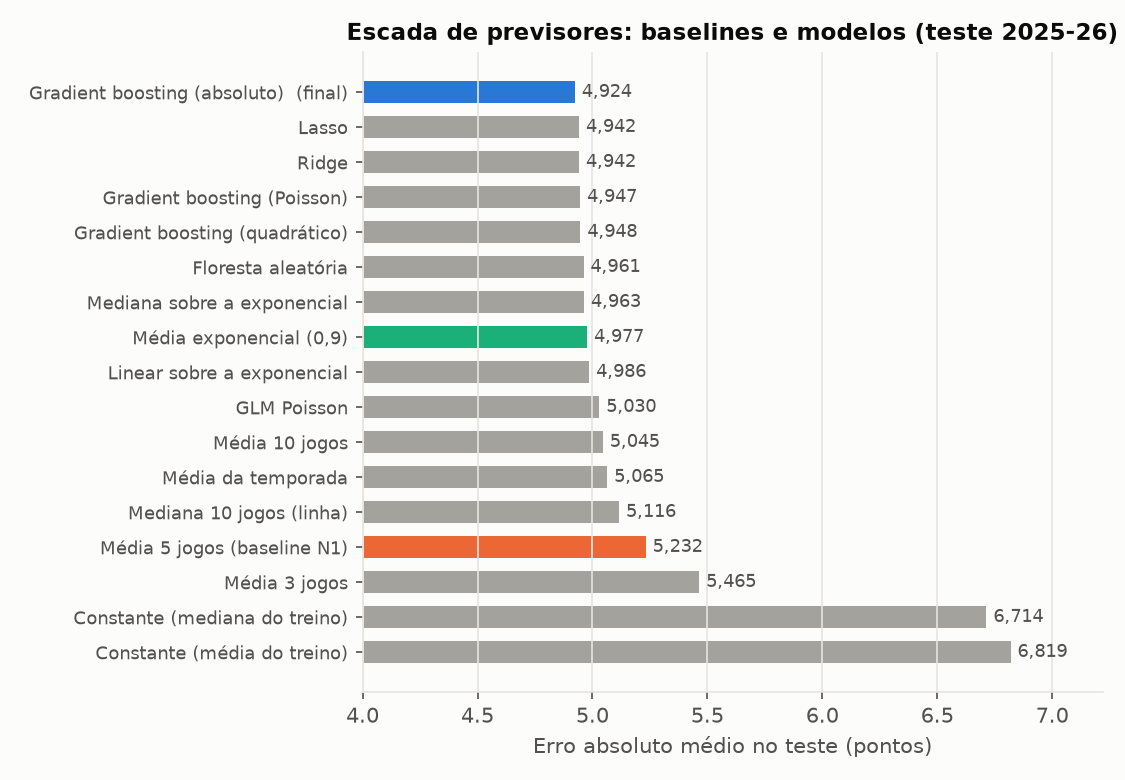

In [9]:
display(Image("results/figures/f_escada_mae.png", width=720))

### Diferenças com intervalo de confiança

Bootstrap pareado **por jogador** (2.000 réplicas): as linhas de um mesmo atleta não são independentes, então o jogador inteiro é a unidade de reamostragem. Delta negativo = o primeiro erra menos.

In [10]:
fin = TF["regressao"]["modelo_final"]
cmp = {k: v for k, v in TF["regressao"]["comparacoes_bootstrap"].items() if k.startswith(fin + "_vs") or k.startswith("ridge_vs")}
dg = TF["regressao"]["diagnosticos_posteriores"]
cmp[fin + "_vs_mediana_sobre_exponencial (diagnóstico posterior)"] = dg["mediana_sobre_exponencial"]["modelo_final_vs_esta"]
print("MAE da regressão mediana sobre a média exponencial:", round(dg["mediana_sobre_exponencial"]["mae_teste"], 3))
pd.DataFrame(cmp).T[["delta", "ic_inf", "ic_sup", "p_valor"]]

MAE da regressão mediana sobre a média exponencial: 4.963


,delta,ic_inf,ic_sup,p_valor
ridge_vs_media_5_jogos,-0.290,-0.322,-0.261,0.000
ridge_vs_media_exponencial,-0.035,-0.050,-0.020,0.000
ridge_vs_linear_sobre_exponencial,-0.044,-0.058,-0.031,0.000
hgb_absoluto_vs_media_5_jogos,-0.308,-0.336,-0.281,0.000
hgb_absoluto_vs_media_exponencial,-0.053,-0.066,-0.041,0.000
hgb_absoluto_vs_linear_sobre_exponencial,-0.063,-0.077,-0.048,0.000
hgb_absoluto_vs_mediana_sobre_exponencial (diagnóstico posterior),-0.040,-0.052,-0.028,0.000


### Resultado esperado (c): a média exponencial supera as médias simples?

In [11]:
pd.DataFrame(TF["regressao"]["exponencial_vs_simples"]).T[["delta", "ic_inf", "ic_sup", "p_valor"]]

,delta,ic_inf,ic_sup,p_valor
media_3_jogos,-0.488,-0.525,-0.452,0.000
media_5_jogos,-0.255,-0.282,-0.230,0.000
media_10_jogos,-0.069,-0.082,-0.055,0.000
media_da_temporada,-0.088,-0.117,-0.061,0.000


## 6. Erro por faixa de minutos e por temporada

In [12]:
faixas = {k: pd.DataFrame(v).set_index("grupo")[["n", "mae", "mae_relativo"]] for k, v in TF["regressao"]["por_faixa_de_minutos"].items()}
pd.concat(faixas, axis=1)

hgb_absoluto                    media_5_jogos                     \
                 n   mae mae_relativo             n   mae mae_relativo   
grupo                                                                    
15-20         3218 3.999        0.563          3218 4.194        0.591   
20-25         4090 4.552        0.470          4090 4.791        0.495   
25-30         4521 4.941        0.384          4521 5.253        0.408   
30-35         3984 5.576        0.322          3984 5.996        0.347   
35+           1288 6.333        0.289          1288 6.787        0.310   

      media_exponencial                     
                      n   mae mae_relativo  
grupo                                       
15-20              3218 4.078        0.574  
20-25              4090 4.589        0.474  
25-30              4521 4.974        0.386  
30-35              3984 5.649        0.327  
35+                1288 6.384        0.292

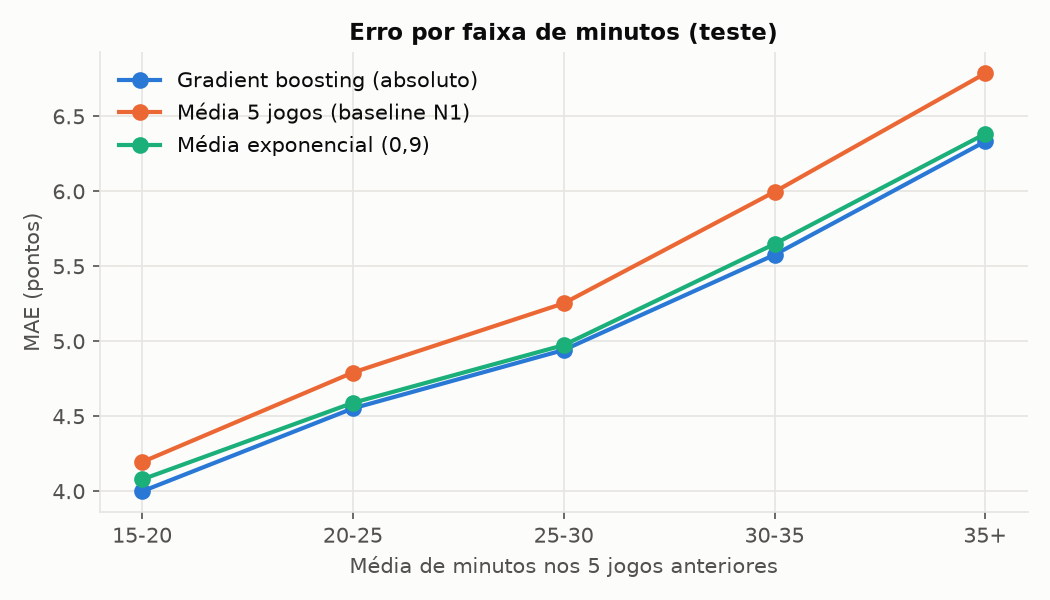

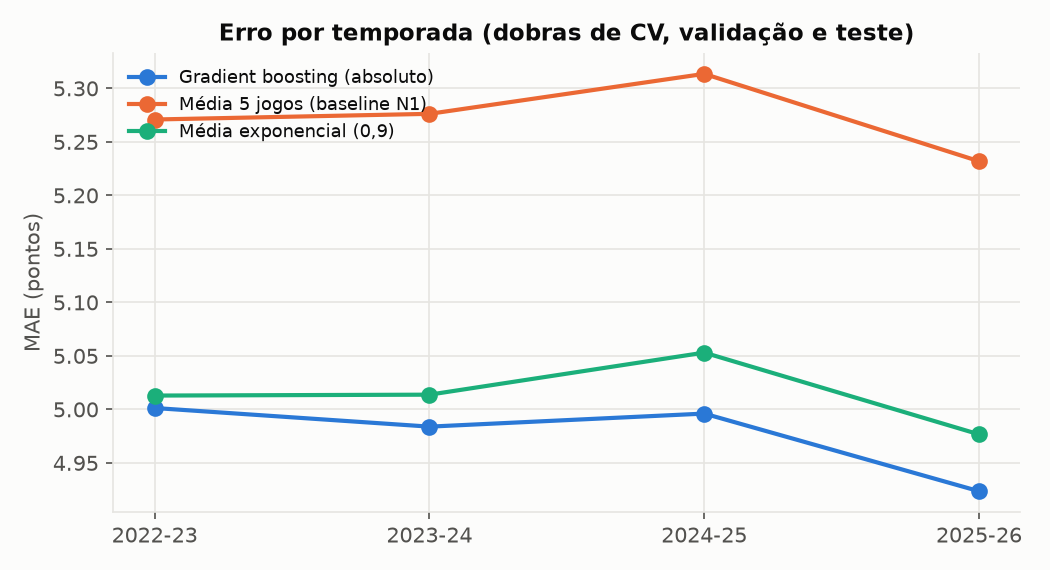

In [13]:
display(Image("results/figures/f_mae_por_faixa_minutos.png", width=640))
display(Image("results/figures/f_mae_por_temporada.png", width=640))

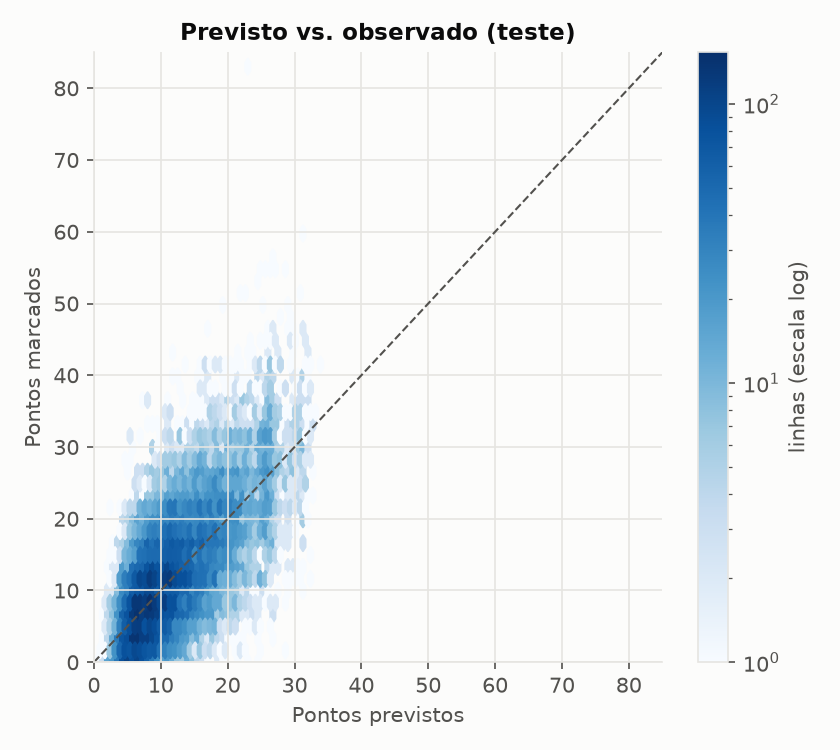

In [14]:
display(Image("results/figures/f_previsto_vs_observado.png", width=520))

## Leitura

- Todos os modelos superam a baseline da N1 (média de 5 jogos) com folga e intervalo de confiança longe de zero.
- Contra a média exponencial o ganho é pequeno (cerca de 1%), mas estatisticamente consistente. Parte dele vem da perda absoluta: contra uma regressão mediana sobre a média exponencial, o ganho cai para cerca de 0,04 ponto, que é a informação que os modelos acrescentam além da média recente.
- O gradient boosting com perda absoluta vence porque otimiza diretamente o MAE: com pontos assimétricos à direita, a mediana erra menos em valor absoluto que a média.
- O erro absoluto cresce com os minutos (quem joga mais pontua mais e oscila mais), mas o erro **relativo** cai.
- O desempenho é estável entre temporadas: não há sinal de deriva forte (os valores de 2022-23 e 2023-24 vêm das dobras usadas para escolher hiperparâmetros e são levemente otimistas).